In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('.').resolve() if (Path('.').resolve() / 'config').exists() else Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from config.settings import (
    FEATURE_NAMES,
    TARGET_COLUMN,
    TARGET_CLASSES,
    PROCESSED_DATASET_DIR,
)
from src.features.feature_engineering import (
    add_engineered_features,
    get_engineered_feature_names,
    ENGINEERED_FEATURE_METADATA,
)
from src.features.feature_selection import (
    split_dataset,
    evaluate_feature_selection_methods,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Phase 4 environment initialized.')

Phase 4 environment initialized.


In [2]:
cleaned_path = PROCESSED_DATASET_DIR / 'cleaned_dry_beans.csv'
df = pd.read_csv(cleaned_path)
print(f'Loaded Cleaned Observations: {len(df):,}')
print(f'Columns: {list(df.columns)}')
df.head()

Loaded Cleaned Observations: 13,543
Columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df_engineered = add_engineered_features(df)
eng_cols = get_engineered_feature_names()
print(f'New features computed: {eng_cols}')
print(f'Total features available: {len(FEATURE_NAMES) + len(eng_cols)}')
display(df_engineered[eng_cols].describe().round(4))

New features computed: ['Area_to_Perimeter', 'Axis_Ratio', 'Axis_Difference', 'Convex_Area_Ratio', 'Compactness_Roundness_Ratio', 'EquivDiameter_to_MajorAxis']
Total features available: 22


,Area_to_Perimeter,Axis_Ratio,Axis_Difference,Convex_Area_Ratio,Compactness_Roundness_Ratio,EquivDiameter_to_MajorAxis
count,13543.0000,13543.0000,13543.0000,13543.0000,13543.0000,13543.0000
mean,58.8866,1.5811,117.5303,1.0130,0.9169,0.8004
std,13.0642,0.2452,54.6649,0.0048,0.0508,0.0615
min,34.3476,1.0249,5.2978,1.0054,0.8400,0.6406
25%,51.4284,1.4307,76.2501,1.0101,0.8865,0.7632
50%,55.9889,1.5499,104.8694,1.0119,0.9036,0.8015
75%,62.7446,1.7039,162.9111,1.0145,0.9303,0.8345
max,131.8209,2.4303,341.6026,1.0878,1.6966,0.9873


In [4]:
train_df, val_df, test_df, split_meta = split_dataset(df_engineered, random_state=42)
print(f'Train Samples: {len(train_df):,} ({split_meta["train_pct"]}%)')
print(f'Validation Samples: {len(val_df):,} ({split_meta["val_pct"]}%)')
print(f'Test Samples: {len(test_df):,} ({split_meta["test_pct"]}%)')

# Verify class balance in each split
split_comp = pd.DataFrame({
    'Class': sorted(df[TARGET_COLUMN].unique()),
    'Train Count': [split_meta['train_class_distribution'][c] for c in sorted(df[TARGET_COLUMN].unique())],
    'Val Count': [split_meta['val_class_distribution'][c] for c in sorted(df[TARGET_COLUMN].unique())],
    'Test Count': [split_meta['test_class_distribution'][c] for c in sorted(df[TARGET_COLUMN].unique())],
})
split_comp['Train %'] = (split_comp['Train Count'] / len(train_df) * 100).round(2)
split_comp['Val %'] = (split_comp['Val Count'] / len(val_df) * 100).round(2)
display(split_comp)

Train Samples: 9,479 (69.99%)
Validation Samples: 2,032 (15.0%)
Test Samples: 2,032 (15.0%)


,Class,Train Count,Val Count,Test Count,Train %,Val %
0,BARBUNYA,926,198,198,9.77,9.74
1,BOMBAY,366,78,78,3.86,3.84
2,CALI,1140,245,245,12.03,12.06
3,DERMASON,2482,532,532,26.18,26.18
4,HOROZ,1302,279,279,13.74,13.73
5,SEKER,1419,304,304,14.97,14.96
6,SIRA,1844,396,396,19.45,19.49


In [5]:
all_feature_names = FEATURE_NAMES + eng_cols
X_train = train_df[all_feature_names]
y_train = train_df[TARGET_COLUMN]

sel_results = evaluate_feature_selection_methods(train_df, y_train, all_feature_names, random_state=42)
rankings_df = sel_results['consolidated_rankings_df']
print('Consolidated Multi-Criteria Feature Rankings (Sorted by Mean Rank):')
display(rankings_df)

Consolidated Multi-Criteria Feature Rankings (Sorted by Mean Rank):


,Feature,MI Score,MI Rank,ANOVA F-Score,ANOVA Rank,RF Importance,RF Rank,RFE Ranking,RFE Selected (Top 10),Mean Rank
Perimeter,ShapeFactor4,0.3628,1,907.70,4,0.0196,1,10,False,2.00
ConvexArea,EquivDiameter,1.0298,2,17921.93,2,0.0490,6,2,False,3.33
MajorAxisLength,ShapeFactor2,0.9509,5,8578.79,7,0.0281,3,8,False,5.00
Area,Area,1.0293,4,20803.07,1,0.0505,11,3,False,5.33
EquivDiameter,roundness,0.7980,3,4711.31,3,0.0283,13,5,False,6.33
MinorAxisLength,ShapeFactor3,0.8298,10,6836.58,6,0.0635,5,1,True,7.00
Area_to_Perimeter,Perimeter,1.0579,8,17270.93,5,0.0930,10,1,True,7.67
ShapeFactor1,Area_to_Perimeter,0.9294,9,16325.74,10,0.0508,4,7,False,7.67
EquivDiameter_to_MajorAxis,Compactness,0.8297,12,7018.20,14,0.0545,2,1,True,9.33
ShapeFactor2,Axis_Ratio,0.8138,6,7157.87,9,0.0316,17,1,True,10.67


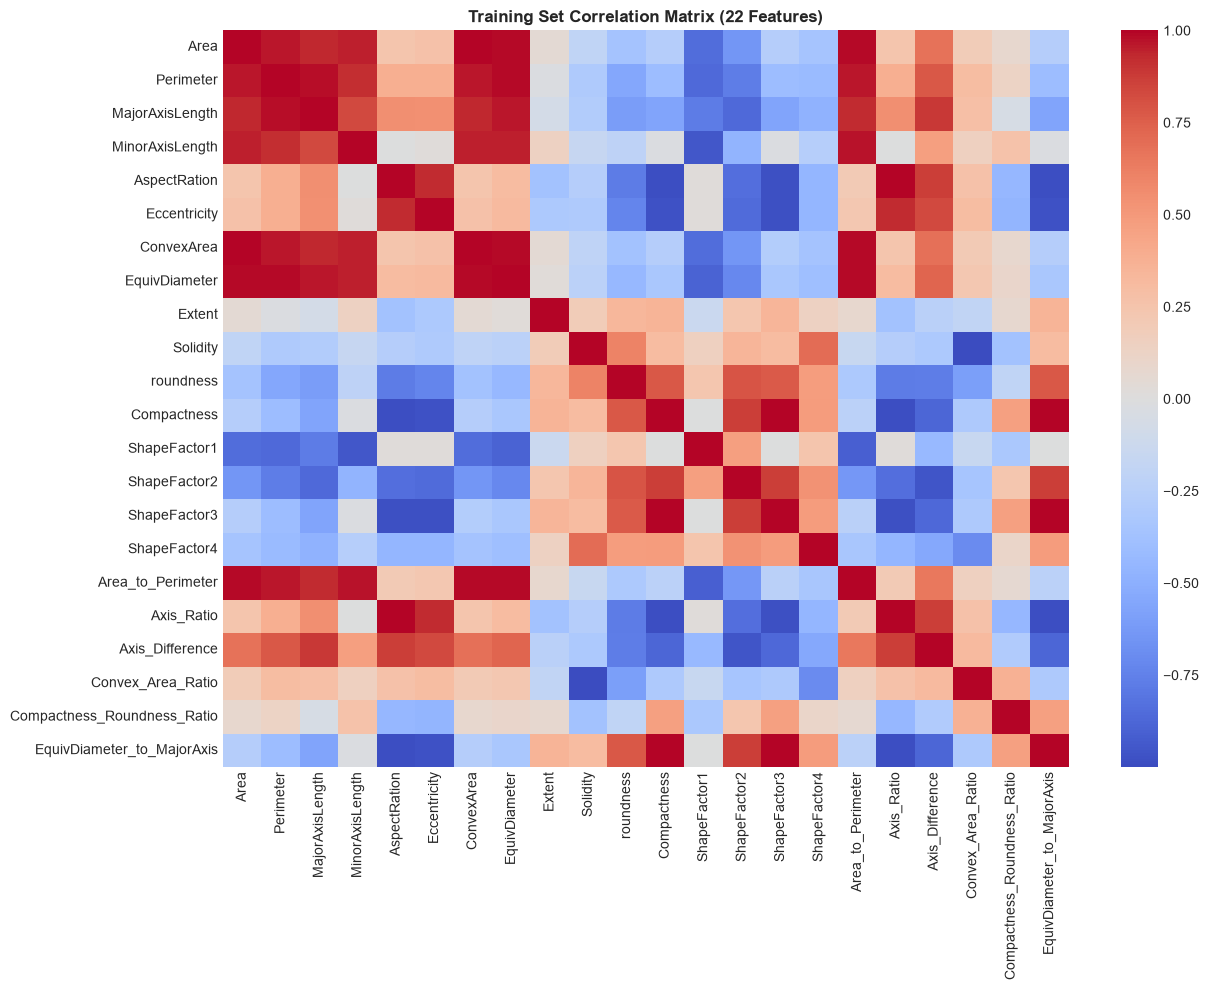

In [6]:
corr_mat = X_train.corr(method='pearson')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_mat, cmap='coolwarm', center=0, annot=False, ax=ax)
ax.set_title('Training Set Correlation Matrix (22 Features)', fontweight='bold')
plt.tight_layout()
plt.show()

,Component,Explained Variance Ratio,Cumulative Variance
0,PC1,0.5559,0.5559
1,PC2,0.2641,0.8200
2,PC3,0.0791,0.8991
3,PC4,0.0513,0.9504
4,PC5,0.0270,0.9774
5,PC6,0.0116,0.9890


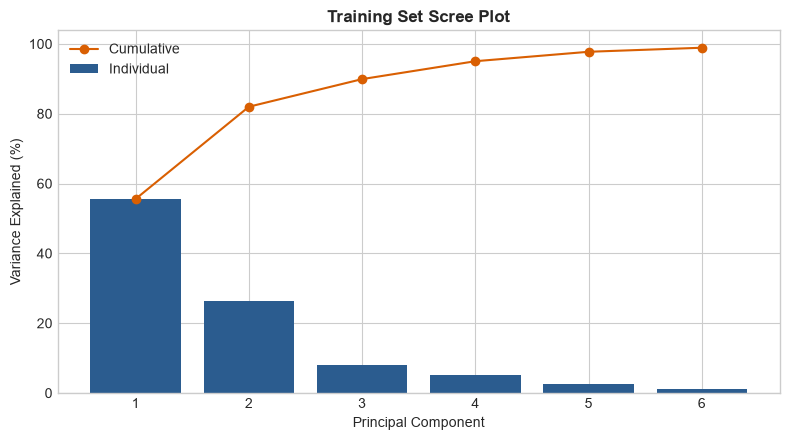

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[FEATURE_NAMES])
pca = PCA(n_components=6, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

pca_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(6)],
    'Explained Variance Ratio': pca.explained_variance_ratio_.round(4),
    'Cumulative Variance': np.cumsum(pca.explained_variance_ratio_).round(4)
})
display(pca_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, 7), pca.explained_variance_ratio_ * 100, color='#2b5c8f', label='Individual')
ax.plot(range(1, 7), np.cumsum(pca.explained_variance_ratio_) * 100, color='#d95f02', marker='o', label='Cumulative')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Variance Explained (%)')
ax.set_title('Training Set Scree Plot', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()